# `residual_effects` in a targeted screen

`cx.tl.residual_effects` adjusts effects for covariates by fitting each gene to them on the control cells
only; a knockdown's effect is the average, over its cells, of observed minus fitted expression. With
`null="model"`, the noise of each effect comes from that control fit, so it suits a **targeted screen**:
one whose targets were chosen for having effects, where the alternative null, the spread across targets,
does not hold. The noise does not depend on the group's own cells, so even small groups, such as a
knockdown within one cell line, are tested.

The method is that of Feng et al. (2026, *Cell Genomics*,
[doi:10.1016/j.xgen.2025.101076](https://doi.org/10.1016/j.xgen.2025.101076)), and the data their targeted
screen: CRISPRi knockdowns in induced pluripotent stem cells from many donors. Effects are estimated per
knockdown and per knockdown in each cell line, with the authors' covariates; their published estimates
serve as a check. crispyx's Wilcoxon rank-sum test is applied to the same groups for comparison.
[Covariate adjustment](../covariate_adjustment.rst) compares `residual_effects` with the other
approaches.

> **Key results**
>
> - With the authors' covariates, the effects match their published ones (Pearson r above 0.9999, slope
>   1.00), and so do the significance calls (the same call for 99.9% of target × gene pairs), per knockdown
>   and per knockdown in each line. Each run takes under a minute.
> - The per-line groups are small, some of only 10 cells, and are still tested reliably: the noise
>   estimate comes from the 535,083 control cells, not from the group.
> - crispyx's Wilcoxon test covers the same groups but agrees less. Against controls from every line,
>   most of its per-line calls are differences between lines. Comparing within lines fixes that, but
>   recovers only 61–67% of the authors' hits.
> - The controls are mostly cells without a detected guide, as in the paper. With only the cells that
>   carry a non-targeting guide as controls, the effects hardly change (r 0.97) and the knockdowns not at
>   all, but the effects on the CRISPRi construct shift and a quarter of the hits are lost to the smaller
>   control set.

**Data.** The targeted screen: 444 knockdowns in 1.16 million cells from 19 lines, captured in 142 10x
inlets, 36,518 genes. The control cells are those with no detected guide plus those with a non-targeting
guide, 535,083 in all, as in the paper. [Check the control cells](control_checks.ipynb) shows that the
cells without a guide differ from those with a non-targeting guide; Part 4 repeats the effects with the
latter alone. Counts and the authors' estimates are public under an MIT licence.

Both methods adjust only for covariates that were recorded. If a knockdown's cells may differ from the
controls in ways no covariate captures, see [causarray](https://causarray.readthedocs.io) (Du *et al.*,
2026, *Briefings in Bioinformatics*, [doi:10.1093/bib/bbag175](https://doi.org/10.1093/bib/bbag175)).

Terms used throughout: a *target* is a knocked-down gene; a *hit* is a target × gene pair whose
Benjamini–Hochberg adjusted p-value, over every pair, is below 0.1, as in the paper.

In [1]:
import os

# Progress bars off, so the saved notebook keeps only crispyx's summary lines; tqdm
# reads this when first imported, so it is set before anything imports tqdm.
os.environ.setdefault('TQDM_DISABLE', '1')

import gzip
import re
import sys
import warnings
from contextlib import contextmanager
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from anndata.io import sparse_dataset, write_elem
from scipy import stats

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', message='A worker stopped while some jobs')
warnings.filterwarnings('ignore', message='Variable names are not unique')  # gene symbols repeat
import crispyx as cx
from crispyx.data import iter_matrix_chunks, read_backed

DATA_DIR = ROOT / 'data' / 'feng'
OUTPUT_DIR = Path('tutorial_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cores = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count()
print(f'crispyx {cx.__version__}, {cores} cores')

steps = []


@contextmanager
def measured(step):
    # record a step's wall time and this process's peak memory while it runs
    with cx.Profiler(timing=True, sampling=True, memory_method='rss', sample_interval=0.5) as profiler:
        yield
    stats_ = profiler.get_stats()
    minutes = stats_['timing']['total_seconds'] / 60
    peak_gb = stats_['memory']['peak_mb'] / 1024
    steps.append({'step': step, 'wall time (min)': round(minutes, 1), 'peak RSS (GB)': round(peak_gb, 1)})
    print(f'{step}: {minutes:.1f} min, peak RSS {peak_gb:.1f} GB')


@contextmanager
def warnings_as_messages():
    # print crispyx's warnings by message only: the default banner names the source file
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        warnings.simplefilter('ignore', DeprecationWarning)
        warnings.filterwarnings('ignore', message='Variable names are not unique')
        yield
    for message in dict.fromkeys(f'{w.category.__name__}: {w.message}' for w in caught):
        print(message)

crispyx 0.2.4, 32 cores


## Get the data

Counts ([doi:10.6084/m9.figshare.27989294](https://doi.org/10.6084/m9.figshare.27989294)) and the authors' effects
([doi:10.6084/m9.figshare.26819743](https://doi.org/10.6084/m9.figshare.26819743)) are on figshare, about 6.5 GB in all. Run once, from the
repository root (this cell is not executed here):

```bash
mkdir -p data/feng && cd data/feng
curl -L -o TargetedScreen_RNA-UMI-Counts.csv.gz https://ndownloader.figshare.com/files/51072902        # 4.5 GB
curl -L -o TargetedScreen_Cell-Metadata.tsv.gz https://ndownloader.figshare.com/files/51051809
curl -L -o TargetedScreen_LFC_byGene.tsv.gz https://ndownloader.figshare.com/files/49291630            # per target
curl -L -o TargetedScreen_LFC_byGene-perLine.tsv.gz https://ndownloader.figshare.com/files/49291675    # per line, 1.9 GB
```

## Part 1 — Prepare the data

### 1. Counts to an h5ad file

The counts come as one CSV with a row per gene and a column per cell. The cell below reads it a gene at a
time and appends each gene's non-zero counts to an h5ad file stored by gene (CSC). `cx.pp.convert_to_csr`
then rewrites it by cell, the layout `residual_effects` streams. The CSV is read a gene at a time;
`convert_to_csr` sizes its buffers to the memory it finds, which explains the peak printed below on a
large machine. Pass `memory_limit_gb=` to cap it.

The counts and the metadata name cells differently (`P1_I1_<barcode>` and `PC-P1-D3_I1_<barcode>`); the
cell below maps one to the other. One cell in the counts has no metadata and is left out later.

> **Watch out:** the matrix holds more than 2³¹ non-zero counts, so its index has to be 64-bit from the
> first block on; anndata cannot widen it later.

In [2]:
counts_path = OUTPUT_DIR / 'FengTS_counts.h5ad'
csc_path = OUTPUT_DIR / 'FengTS_counts_csc.h5ad'
metadata = pd.read_csv(DATA_DIR / 'TargetedScreen_Cell-Metadata.tsv.gz', sep='\t', index_col='Cell_ID')

with measured('counts CSV to h5ad'), warnings_as_messages():
    with gzip.open(DATA_DIR / 'TargetedScreen_RNA-UMI-Counts.csv.gz', 'rt') as csv:
        # the counts name cells P1_I1_<barcode>; the metadata, PC-P1-D3_I1_<barcode>
        cells = csv.readline().rstrip('\n').split(',')[1:]
        cell_ids = [re.sub(r'^P(\d+)_I(\d+)_', r'PC-P\1-D3_I\2_', c) for c in cells]
        obs = metadata.reindex(cell_ids).astype('category')
        genes, block = [], []
        with h5py.File(csc_path, 'w') as h5:
            h5.attrs['encoding-type'], h5.attrs['encoding-version'] = 'anndata', '0.1.0'
            write_elem(h5, 'obs', obs.rename_axis(None))
            for line in csv:  # one gene per line: its counts in every cell
                name, values = line.split(',', 1)
                genes.append(name)
                block.append(sp.csc_matrix(np.fromstring(values, dtype=np.float32, sep=',')[:, None]))
                if len(block) == 512:
                    columns = sp.hstack(block, format='csc')
                    if 'X' in h5:
                        sparse_dataset(h5['X']).append(columns)
                    else:
                        columns.indptr = columns.indptr.astype(np.int64)  # over 2**31 non-zeros in all
                        write_elem(h5, 'X', columns)
                    block = []
            sparse_dataset(h5['X']).append(sp.hstack(block, format='csc'))
            ids = pd.Series(genes).str.split(':', expand=True)  # ENSG...:SYMBOL:Gene-Expression
            write_elem(h5, 'var', pd.DataFrame({'gene_name': ids[1].to_numpy()}, index=ids[0].to_numpy()))
    cx.pp.convert_to_csr(csc_path, output_path=counts_path)
    csc_path.unlink()
print(f"{len(cells):,} cells ({obs['Guide_Call'].notna().sum():,} in the metadata) x {len(genes):,} genes")

[cx] pp.convert_to_csr: tutorial_outputs/FengTS_counts_csc.h5ad → tutorial_outputs/FengTS_counts.h5ad
[cx] pp.convert_to_csr: chunk_size=4096 (auto)
[cx] pp.convert_to_csr: Done  1161865 cells × 36518 genes
counts CSV to h5ad: 36.0 min, peak RSS 66.2 GB
1,161,865 cells (1,161,864 in the metadata) x 36,518 genes


### 2. Labels and the authors' covariates

The authors' control model (their script `6a_run_control_lm.R`) is

`expression ~ cell line + inlet + total counts + % mitochondrial + S score + G2M score`.

The metadata has the line and the inlet (`Batch`). The other four are computed here in two streaming
passes: total and mitochondrial counts per cell, then Seurat's cell-cycle scores, using the
`cc.genes.updated.2019` gene lists the authors scored with. A score is a gene set's mean expression minus
that of control genes with similar expression. Seurat draws the control genes at random, and the authors
scored each inlet separately, so these scores match theirs only approximately.

Each cell's label is the target of its guide. Cells with no detected guide or a non-targeting guide are
the controls, as in the paper. 98% of them have no detected guide; Part 4 uses the non-targeting cells
alone.

In [3]:
# Seurat's cell-cycle genes (cc.genes.updated.2019), which the authors scored with CellCycleScoring
S_GENES = ('MCM5 PCNA TYMS FEN1 MCM7 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 CENPU HELLS RFC2 POLR1B '
           'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
           'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B MRPL36 E2F8').split()
G2M_GENES = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 PIMREG '
             'SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 JPT1 CDC20 TTK '
             'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 '
             'CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA').split()

symbols = cx.load_var(counts_path)['gene_name'].astype(str).to_numpy()
first_column = {}
for column, symbol in enumerate(symbols):
    first_column.setdefault(symbol, column)  # a few symbols repeat; take the first, as Seurat does
mito_columns = np.flatnonzero(pd.Index(symbols).str.startswith('MT-'))


def log_cp10k(block, totals):
    # log1p of counts per 10,000, a row chunk at a time
    scaled = sp.csr_matrix(block.multiply(1e4 / np.maximum(totals, 1)[:, None]))
    scaled.data = np.log1p(scaled.data)
    return scaled


with measured('covariates: depth, mitochondrial share, cell cycle'):
    # pass 1: each cell's total and mitochondrial counts, each gene's mean expression
    backed = read_backed(counts_path)
    totals, mito, gene_sum = [], [], np.zeros(len(symbols))
    for _, block in iter_matrix_chunks(backed, chunk_size=16384, convert_to_dense=False, read_ahead=True):
        total = np.asarray(block.sum(axis=1)).ravel()
        totals.append(total)
        mito.append(np.asarray(block[:, mito_columns].sum(axis=1)).ravel())
        gene_sum += np.asarray(log_cp10k(block, total).sum(axis=0)).ravel()
    backed.file.close()
    totals, mito = np.concatenate(totals), np.concatenate(mito)

    # Seurat's module score: mean expression of a gene set minus that of control genes drawn
    # from the same expression bin (24 bins; as many per gene as the smaller set has genes)
    rng = np.random.default_rng(1)
    gene_mean = gene_sum / len(totals)
    bins = pd.qcut(gene_mean, 24, labels=False, duplicates='drop')
    n_control = min(len(S_GENES), len(G2M_GENES))

    def module(gene_set):
        features = np.array(sorted(first_column[g] for g in gene_set if g in first_column))
        controls = np.unique(np.concatenate(
            [rng.choice(np.flatnonzero(bins == bins[f]), n_control, replace=False) for f in features]))
        return features, controls

    modules = {'S_score': module(S_GENES), 'G2M_score': module(G2M_GENES)}
    columns = np.unique(np.concatenate([np.concatenate(m) for m in modules.values()]))
    where = pd.Series(np.arange(len(columns)), index=columns)
    scores = {name: [] for name in modules}
    backed = read_backed(counts_path)
    for slc, block in iter_matrix_chunks(backed, chunk_size=16384, convert_to_dense=False, read_ahead=True):
        expression = log_cp10k(block[:, columns], totals[slc]).toarray()
        for name, (features, controls) in modules.items():
            scores[name].append(expression[:, where[features]].mean(axis=1)
                                - expression[:, where[controls]].mean(axis=1))
    backed.file.close()

    obs = cx.load_obs(counts_path)
    obs['total_counts'] = totals
    obs['percent_mt'] = 100 * mito / np.maximum(totals, 1)
    for name in scores:
        obs[name] = np.concatenate(scores[name])
    obs['inlet'], obs['line'] = obs['Batch'], obs['Cell_Line']
    cx.write_obs(counts_path, obs)

guide_target = obs['Guide_Call'].astype(str).str.split('_').str[0]
labels = (guide_target.where(~guide_target.isin(['unassigned', 'NonTarget']), 'control')
          .where(obs['Guide_Call'].notna())  # the one cell without metadata is left out
          .rename('target'))
covariates = ['line', 'inlet', 'total_counts', 'percent_mt', 'S_score', 'G2M_score']
print(f"{(labels == 'control').sum():,} control cells, {labels[labels != 'control'].nunique():,} targets; "
      f"median {np.median(totals):,.0f} counts per cell, {np.median(obs['percent_mt']):.1f}% mitochondrial")

covariates: depth, mitochondrial share, cell cycle: 1.8 min, peak RSS 14.5 GB
535,083 control cells, 444 targets; median 18,614 counts per cell, 3.3% mitochondrial


## Part 2 — Effects with the authors' covariates

### 3. Effects per target

`null='model'` is the authors' test: the effect divided by the control fit's residual standard deviation
over √n. It suits a targeted screen; the robust null assumes most targets leave a gene unchanged, which
a screen of chosen targets does not satisfy. `min_cells=10` is the paper's threshold.

In [4]:
with measured('residual_effects, per target'):
    per_target = cx.tl.residual_effects(
        counts_path, labels, 'control', covariates=covariates, null='model', min_cells=10,
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'fengts_residual_effects.h5ad',
    )
per_target

[cx] residual_effects: Reading tutorial_outputs/FengTS_counts.h5ad
[cx] residual_effects: 444 perturbations, 535,083 control cells, design: 164 columns
[cx] residual_effects: the design has rank 163 < 164 columns (collinear covariates); every perturbation's design lies within the controls', so its effect is still unique.
[cx] residual_effects: estimated disk usage: 570.7 MB (5.5 TB free)
[cx] residual_effects: 444 perturbations x 36,518 genes (8,192 tested), model null
[cx] residual_effects: Saving → tutorial_outputs/fengts_residual_effects.h5ad
residual_effects, per target: 0.5 min, peak RSS 17.6 GB


AnnData(path=tutorial_outputs/fengts_residual_effects.h5ad, mode='r')

### 4. Compare with the authors' estimates

The authors' table holds, for each target and each of their 6,515 expressed genes, the effect (`lfc`,
like ours a difference of `log1p(CP10k)`, observed minus expected) and the adjusted p-value.
`residual_effects` adjusts p-values within each target, so here they are re-adjusted over every pair, as
the authors did. The table gives the correlation and slope of our effects against theirs, the share of
pairs each calls significant, and the share that get the same call.

In [5]:
def read_table(name, by_line):
    # one of the authors' effect tables, keyed like our rows: target, or target|line
    table = pd.read_csv(DATA_DIR / name, sep='\t')
    table['row'] = table['Target'].astype(str) + ('|' + table['Cell_Line'].astype(str) if by_line else '')
    return table


def lookup(path, table, layers):
    # values of an h5ad result at the table's (row, gene) pairs; NaN where the result has none
    with h5py.File(path, 'r') as h5:
        index = lambda group: pd.Index(group[group.attrs['_index']][:].astype(str))
        rows, genes = index(h5['obs']), index(h5['var'])
        first = pd.Series(np.arange(len(genes)), index=genes)
        first = first[~first.index.duplicated()]  # a few symbols repeat; take the first
        r = rows.get_indexer(table['row'])
        g = first.reindex(table['Expressed_Gene_Symbol']).fillna(-1).to_numpy(dtype=int)
        found = (r >= 0) & (g >= 0)
        out = {}
        for name in layers:
            values = np.full(len(table), np.nan)
            values[found] = h5[name][:][r[found], g[found]]
            out[name] = values
    return out


def against_paper(table, values):
    # our effect and significance (BH over every pair, as the authors) next to theirs
    effect, p = values['X'], values['layers/pvalue']
    tested = np.isfinite(p)
    q = np.full(p.shape, np.nan)
    q[tested] = stats.false_discovery_control(p[tested])
    paper_sig, ours_sig = table['pval_adj'].to_numpy() < 0.1, q < 0.1
    lfc = table['lfc'].to_numpy()
    return {
        'rows': table.loc[tested, 'row'].nunique(), 'pairs': int(tested.sum()),
        'effect r': np.corrcoef(effect[tested], lfc[tested])[0, 1],
        'slope': np.polyfit(lfc[tested], effect[tested], 1)[0],
        'significant, paper': paper_sig[tested].mean(), 'significant, ours': ours_sig[tested].mean(),
        'same call': np.mean(paper_sig[tested] == ours_sig[tested]),
    }


paper_target = read_table('TargetedScreen_LFC_byGene.tsv.gz', by_line=False)
ours_target = lookup(per_target.path, paper_target, ['X', 'layers/pvalue'])
reproduction = {'per target': against_paper(paper_target, ours_target)}
pd.DataFrame(reproduction).T.astype({'rows': int, 'pairs': int}).round(5)

,rows,pairs,effect r,slope,"significant, paper","significant, ours",same call
per target,444,2872680,0.99996,0.99969,0.10592,0.10534,0.99868


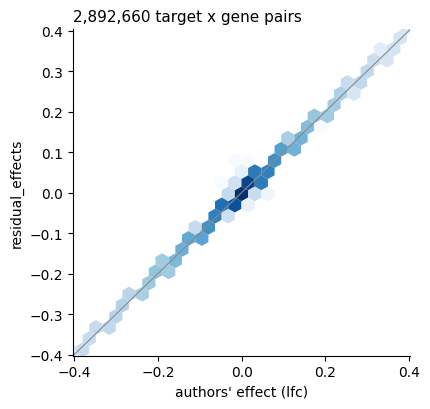

In [6]:
tested = np.isfinite(ours_target['X'])
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.hexbin(paper_target['lfc'].to_numpy()[tested], ours_target['X'][tested], gridsize=80, bins='log',
          cmap='Blues', mincnt=1, linewidths=0)
lim = np.nanpercentile(np.abs(paper_target['lfc']), 99.99)
ax.plot([-lim, lim], [-lim, lim], color='#8a8a85', linewidth=0.8)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("authors' effect (lfc)")
ax.set_ylabel('residual_effects')
ax.set_title(f'{tested.sum():,} target x gene pairs', loc='left', fontsize=11)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

The effects agree to the fourth decimal, and the calls differ for about one pair in a thousand, within
what the approximate cell-cycle scores explain.

### 5. Effects per target and cell line

The authors also report each knockdown's effect in each line where it has at least 10 cells: 8,204
groups. The labels become `target|line`. The control fit is the same, so even the smallest groups take
their noise estimate from it.

In [7]:
by_line = (labels + '|' + obs['line'].astype(str)).where(labels.ne('control'), labels).rename('target_line')
with measured('residual_effects, per target and line'):
    per_line = cx.tl.residual_effects(
        counts_path, by_line, 'control', covariates=covariates, null='model', min_cells=10,
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'fengts_residual_effects_per_line.h5ad',
    )
paper_line = read_table('TargetedScreen_LFC_byGene-perLine.tsv.gz', by_line=True)
ours_line = lookup(per_line.path, paper_line, ['X', 'layers/pvalue'])
reproduction['per target and line'] = against_paper(paper_line, ours_line)
pd.DataFrame(reproduction).T.astype({'rows': int, 'pairs': int}).round(5)

[cx] residual_effects: Reading tutorial_outputs/FengTS_counts.h5ad
[cx] residual_effects: 228 perturbation(s) have fewer than 10 cells and are left out: ['SPAST|pipw_5', 'SRP14|pipw_5', 'BCL2L1|pipw_5', 'CLN3|pipw_5', 'RPLP2|pipw_5', 'EIF4G1|pipw_5', 'HMGCS1|pipw_5', 'ITGAV|pipw_5', 'BCL2L1|jejf_3', 'SEC62|pipw_5']
[cx] residual_effects: 8,207 perturbations, 535,083 control cells, design: 164 columns
[cx] residual_effects: the design has rank 163 < 164 columns (collinear covariates); every perturbation's design lies within the controls', so its effect is still unique.
[cx] residual_effects: estimated disk usage: 10.5 GB (5.5 TB free)
[cx] residual_effects: 8,207 perturbations x 36,518 genes (8,192 tested), model null
[cx] residual_effects: Saving → tutorial_outputs/fengts_residual_effects_per_line.h5ad
residual_effects, per target and line: 0.7 min, peak RSS 14.7 GB


,rows,pairs,effect r,slope,"significant, paper","significant, ours",same call
per target,444,2872680,0.99996,0.99969,0.10592,0.10534,0.99868
per target and line,8204,53079880,0.99996,1.00015,0.00447,0.00439,0.99990


## Part 3 — crispyx's Wilcoxon test

### 6. The same groups, tested by ranks

A rank test needs normalised data, so the counts are normalised to `log1p(CP10k)` and restricted to the
8,192 genes `residual_effects` tested (control mean above 0.1). Each group is tested two ways: against
every control cell, and stratified by line (`batch_column='line'`), each line's cells against that line's
controls.

In [8]:
tested_genes = per_target.backed.var['tested'].to_numpy()
with measured('normalise and keep the tested genes'), warnings_as_messages():
    normalised = cx.pp.normalize_total_log1p(counts_path, OUTPUT_DIR / 'FengTS_log1p.h5ad')
    cx.write_filtered_subset(
        normalised.path, cell_mask=np.ones(len(obs), dtype=bool), gene_mask=tested_genes,
        output_path=OUTPUT_DIR / 'FengTS_log1p_tested.h5ad',
    )
    Path(normalised.path).unlink()
expressed_path = OUTPUT_DIR / 'FengTS_log1p_tested.h5ad'

# every cell needs a label here; the one without metadata gets its own, never tested
target_labels = labels.fillna('no metadata')
line_labels = by_line.fillna('no metadata')
wilcoxon = {}
for level, lab in (('per target', target_labels), ('per target and line', line_labels)):
    sizes = lab.value_counts()
    groups = sizes.index[(sizes >= 10) & ~sizes.index.isin(['control', 'no metadata'])].tolist()
    for strata, batch in (('pooled controls', None), ('stratified by line', 'line')):
        with measured(f'wilcoxon_test, {level}, {strata}'), warnings_as_messages():
            wilcoxon[level, strata] = cx.wilcoxon_test(
                expressed_path, perturbation_column=lab, control_label='control', perturbations=groups,
                batch_column=batch, gene_name_column='gene_name', verbose=0,
                output_path=OUTPUT_DIR / f"fengts_wilcoxon_{level.replace(' ', '_')}_{strata.replace(' ', '_')}.h5ad",
            )

[cx] pp.normalize_total_log1p: Saving → tutorial_outputs/FengTS_log1p.h5ad
[cx] pp.normalize_total_log1p: Done  1161865 cells × 36518 genes
normalise and keep the tested genes: 1.8 min, peak RSS 18.7 GB
wilcoxon_test, per target, pooled controls: 2.3 min, peak RSS 145.3 GB
wilcoxon_test, per target, stratified by line: 2.2 min, peak RSS 155.4 GB
wilcoxon_test, per target and line, pooled controls: 3.6 min, peak RSS 146.6 GB
wilcoxon_test, per target and line, stratified by line: 2.4 min, peak RSS 157.7 GB


In [9]:
def recovery(table, sign, p):
    # how a method's calls (BH over every pair) line up with the authors'
    tested = np.isfinite(p)
    q = np.full(p.shape, np.nan)
    q[tested] = stats.false_discovery_control(p[tested])
    ours, theirs = q < 0.1, table['pval_adj'].to_numpy() < 0.1
    both = tested & theirs
    return {
        'groups tested': table.loc[tested, 'row'].nunique() / table['row'].nunique(),
        'paper hits recovered': ours[theirs].mean(),
        'calls that are paper hits': theirs[ours].mean(),
        'same sign on paper hits': np.mean(np.sign(sign[both]) == np.sign(table['lfc'].to_numpy()[both])),
    }


rows = {}
for level, table, residual in (('per target', paper_target, ours_target), ('per target and line', paper_line, ours_line)):
    rows[level, 'residual_effects'] = recovery(table, residual['X'], residual['layers/pvalue'])
    for strata in ('pooled controls', 'stratified by line'):
        values = lookup(wilcoxon[level, strata].result_path, table, ['layers/z_score', 'layers/pvalue'])
        rows[level, f'wilcoxon, {strata}'] = recovery(table, values['layers/z_score'], values['layers/pvalue'])
pd.DataFrame(rows).T.rename_axis(['level', 'method']).round(3)

groups tested  \
level               method                                        
per target          residual_effects                        1.0   
                    wilcoxon, pooled controls               1.0   
                    wilcoxon, stratified by line            1.0   
per target and line residual_effects                        1.0   
                    wilcoxon, pooled controls               1.0   
                    wilcoxon, stratified by line            1.0   

                                                  paper hits recovered  \
level               method                                               
per target          residual_effects                             0.988   
                    wilcoxon, pooled controls                    0.780   
                    wilcoxon, stratified by line                 0.671   
per target and line residual_effects                             0.970   
                    wilcoxon, pooled controls                    0.771   
                    wilcoxon, stratified by line                 0.613   

                                                  calls that are paper hits  \
level               method                                                    
per target          residual_effects                                  0.997   
                    wilcoxon, pooled controls                         0.520   
                    wilcoxon, stratified by line                      0.870   
per target and line residual_effects                                  0.998   
                    wilcoxon, pooled controls                         0.037   
                    wilcoxon, stratified by line                      0.823   

                                                  same sign on paper hits  
level               method                                                 
per target          residual_effects                                1.000  
                    wilcoxon, pooled controls                       0.978  
                    wilcoxon, stratified by line                    0.993  
per target and line residual_effects                                1.000  
                    wilcoxon, pooled controls                       0.940  
                    wilcoxon, stratified by line                    0.998

Both methods test every group the authors did. They differ in what they call:

- **Against controls from every line**, the Wilcoxon test reads differences between lines as effects.
  Per line, only 3.7% of its calls are the authors' hits.
- **Stratified by line**, most of its calls are the authors' hits (82–87%), but it finds only 61–67% of
  them. Ranks of mostly zero counts carry less information than a mean, and it adjusts for line only, not
  for inlet, depth, mitochondrial share or cell cycle.
- `residual_effects` finds 97–99% of the authors' hits, and over 99% of its calls are among them.

## Part 4 — Controls without the unassigned cells

98% of the controls above are cells with no detected guide. [Check the control cells](control_checks.ipynb)
shows that they differ from the cells with a non-targeting guide: less of the CRISPRi construct, and lower
expression of the screen's targets. Here the per-target effects are estimated again with only the 8,241
non-targeting cells as controls (the unassigned cells get no label and are left out), with the same
covariates, and compared with Part 2's.

In [10]:
nontarget_labels = labels.where(obs['Guide_Call'].astype(str).ne('unassigned')).rename('target')
with measured('residual_effects, per target, non-targeting controls'):
    per_target_nt = cx.tl.residual_effects(
        counts_path, nontarget_labels, 'control', covariates=covariates, null='model', min_cells=10,
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'fengts_residual_effects_nontarget_controls.h5ad',
    )

[cx] residual_effects: Reading tutorial_outputs/FengTS_counts.h5ad
[cx] residual_effects: 444 perturbations, 8,241 control cells, design: 164 columns
[cx] residual_effects: the design has rank 163 < 164 columns (collinear covariates); every perturbation's design lies within the controls', so its effect is still unique.
[cx] residual_effects: estimated disk usage: 570.7 MB (5.5 TB free)
[cx] residual_effects: 444 perturbations x 36,518 genes (8,196 tested), model null
[cx] residual_effects: Saving → tutorial_outputs/fengts_residual_effects_nontarget_controls.h5ad
residual_effects, per target, non-targeting controls: 0.4 min, peak RSS 28.4 GB


In [11]:
def read_effects(path):
    # a residual_effects result: targets, genes, effects and p-values
    with h5py.File(path, 'r') as h5:
        index = lambda group: pd.Index(group[group.attrs['_index']][:].astype(str))
        return index(h5['obs']), index(h5['var']), h5['X'][:], h5['layers/pvalue'][:]


def bh_hits(p):
    # BH over every tested pair, as the authors
    tested = np.isfinite(p)
    q = np.full(p.shape, np.nan)
    q[tested] = stats.false_discovery_control(p[tested])
    return q < 0.1


targets, genes, effect_all, p_all = read_effects(per_target.path)
targets_nt, genes_nt, effect_nt, p_nt = read_effects(per_target_nt.path)
assert targets.equals(targets_nt) and genes.equals(genes_nt)
both = np.isfinite(p_all) & np.isfinite(p_nt)  # pairs tested in both runs
hits_all, hits_nt = bh_hits(p_all) & both, bh_hits(p_nt) & both
first = pd.Series(np.arange(len(genes)), index=genes)
own_gene = first[~first.index.duplicated()].reindex(targets)  # each target's own gene
known = own_gene.notna().to_numpy()
own = (np.flatnonzero(known), own_gene[known].astype(int).to_numpy())

x, y = effect_all[both], effect_nt[both]
print(f'{both.sum():,} pairs tested in both: effect r {np.corrcoef(x, y)[0, 1]:.3f}, '
      f'slope {np.polyfit(x, y, 1)[0]:.3f}; {(hits_all & hits_nt).sum() / hits_all.sum():.0%} of the hits '
      f'with all controls are hits with non-targeting controls only')
pd.DataFrame({
    'control cells': [(labels == 'control').sum(), (nontarget_labels == 'control').sum()],
    'hits': [hits_all.sum(), hits_nt.sum()],
    'hits per target (median)': [np.median(hits_all.sum(axis=1)), np.median(hits_nt.sum(axis=1))],
    'own gene: effect (median)': [np.nanmedian(effect_all[own]), np.nanmedian(effect_nt[own])],
    'own gene: hit': [hits_all[own].sum(), hits_nt[own].sum()],
}, index=['all controls (the paper)', 'non-targeting controls only']).round(3)

3,609,720 pairs tested in both: effect r 0.966, slope 0.979; 74% of the hits with all controls are hits with non-targeting controls only


,control cells,hits,hits per target (median),own gene: effect (median),own gene: hit
all controls (the paper),535083,339087,316.0,-0.313,393
non-targeting controls only,8241,284599,234.5,-0.309,392


Changing the controls changes only the control fit, so a gene's effect shifts by about the same amount in
every target. The genes that shift most:

In [12]:
tested_genes_both = both.any(axis=0)
shift = pd.Series(np.nanmedian(np.where(both, effect_nt - effect_all, np.nan)[:, tested_genes_both], axis=0),
                  index=genes[tested_genes_both], name='effect shift, non-targeting minus all controls')
top_shift = shift.abs() >= shift.abs().quantile(0.99)
lost = (hits_all & ~hits_nt)[:, tested_genes_both].sum(axis=0)
print(f'the 1% most shifted genes hold {lost[top_shift.to_numpy()].sum() / lost.sum():.1%} of the hits lost')
shift.reindex(shift.abs().sort_values(ascending=False).index).head(10).round(3).to_frame()

the 1% most shifted genes hold 4.4% of the hits lost


,"effect shift, non-targeting minus all controls"
dCas9-KRAB-MeCP2,-0.049
HIST1H4C,-0.033
EIF4EBP1,-0.030
CHCHD2,0.026
ID3,-0.026
TUBB3,0.024
RPL22L1,-0.024
BSD,0.024
KIF5B,0.024
PSAT1,-0.023


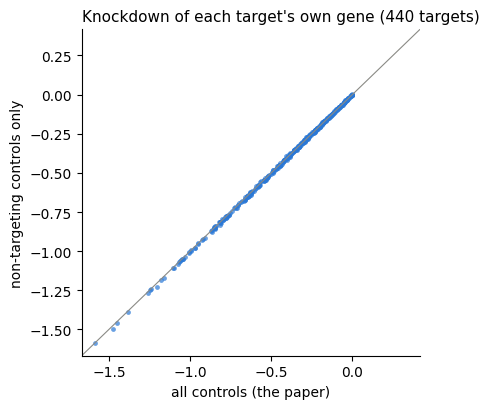

In [13]:
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(effect_all[own], effect_nt[own], s=12, color='#2a78d6', alpha=0.7, linewidths=0)
lim = np.nanmax(np.abs(np.concatenate([effect_all[own], effect_nt[own]]))) * 1.05
ax.plot([-lim, lim], [-lim, lim], color='#8a8a85', linewidth=0.8)
ax.set_xlim(-lim, lim / 4)
ax.set_ylim(-lim, lim / 4)
ax.set_xlabel('all controls (the paper)')
ax.set_ylabel('non-targeting controls only')
ax.set_title(f'Knockdown of each target\'s own gene ({known.sum()} targets)', loc='left', fontsize=11)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

- **The effects hardly change** (r 0.97, slope 0.98 over 3.6 million pairs), and each target's knockdown of
  its own gene not at all: median −0.31 either way, significant for 393 and 392 of the 440 targets.
- **The genes that shift most are the screen's own construct**: the CRISPRi effector `dCas9-KRAB-MeCP2`
  and the blasticidin selection marker (`BSD`). Against all controls every target seems to carry about 0.05
  more effector, because the unassigned cells carry less. Effects on these genes reflect the choice of
  controls, not the knockdown.
- **The smaller control set finds fewer hits**: 234 per target instead of 316 (median), and 74% of the hits
  with all controls are found again. The hits lost are not in the shifted genes (the 1% most shifted hold
  4% of them); they are pairs near the threshold.

For this screen, pooling the unassigned cells, as the authors did, changes the effects little and adds
power, but biases the construct genes. Non-targeting controls alone avoid that bias at the cost of a
quarter of the hits.

## Resources

Wall time and peak memory of this notebook's process for each step. Converting the CSV takes most of the
time. The Wilcoxon test holds far more in memory than `residual_effects`.

In [14]:
resources = pd.DataFrame(steps).set_index('step')
resources.loc['total'] = [resources['wall time (min)'].sum(), resources['peak RSS (GB)'].max()]
resources

,wall time (min),peak RSS (GB)
step,,
counts CSV to h5ad,36.0,66.2
"covariates: depth, mitochondrial share, cell cycle",1.8,14.5
"residual_effects, per target",0.5,17.6
"residual_effects, per target and line",0.7,14.7
normalise and keep the tested genes,1.8,18.7
"wilcoxon_test, per target, pooled controls",2.3,145.3
"wilcoxon_test, per target, stratified by line",2.2,155.4
"wilcoxon_test, per target and line, pooled controls",3.6,146.6
"wilcoxon_test, per target and line, stratified by line",2.4,157.7


## Takeaways

- `residual_effects`, with the authors' covariates and `null='model'`, **reproduces their published
  effects and significance calls**, per target and per target in each line, in under a minute each.
- **Small groups are not a problem for it**: the noise estimate comes from the control cells.
- **For per-line effects, compare each line with its own controls.** Against pooled controls, a rank test
  reports mostly differences between lines.
- **Check the controls before pooling cells without a guide into them** (`cx.pp.compare_controls`).
  Here pooling them changes the effects little and adds power, except on the CRISPRi construct and the
  vector's markers; non-targeting controls alone avoid that bias at the cost of a quarter of the hits.
- **In a screen of chosen targets, use** `null='model'`, as here. The robust null assumes most targets
  leave a given gene unchanged.